<a href="https://colab.research.google.com/github/harshhlf2024-cmyk/minor-1/blob/main/Minor_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 0: Import libraries and load dataset

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
from google.colab import files
uploaded = files.upload()

Saving AB_NYC 2019.csv to AB_NYC 2019 (1).csv


In [12]:
df = pd.read_csv(next(iter(uploaded)))
print(df.shape)
df.head()

(48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## Step 1: EDA


In [13]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [14]:
print("Numerical columns:", df.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", df.select_dtypes(include="object").columns.tolist())

Numerical columns: ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical columns: ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [15]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing)

,Missing Values,Percentage
id,0,0.00
name,16,0.03
host_id,0,0.00
host_name,21,0.04
neighbourhood_group,0,0.00
neighbourhood,0,0.00
latitude,0,0.00
longitude,0,0.00
room_type,0,0.00
price,0,0.00


## Step 2: Data cleaning

In [17]:
data = df.copy()
drop_cols = ["last_review", "id", "host_id", "name", "host_name",
             "neighbourhood", "host_name", "last_review"]
data.drop(columns=[c for c in drop_cols if c in data.columns], inplace=True)

In [20]:
if "reviews_per_month" in data.columns:
    data.loc[(data["reviews_per_month"].isnull()) &
             (data["number_of_reviews"] == 0), "reviews_per_month"] = 0
    data["reviews_per_month"] = data["reviews_per_month"].fillna(
        data["reviews_per_month"].median()
    )

print(data.isnull().sum())

neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64


## Step 3: Outlier detection and treatment

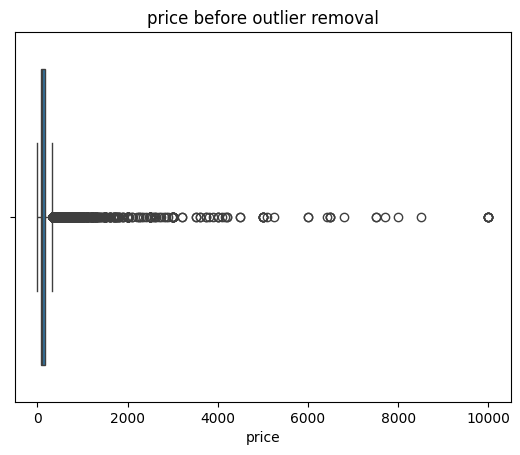

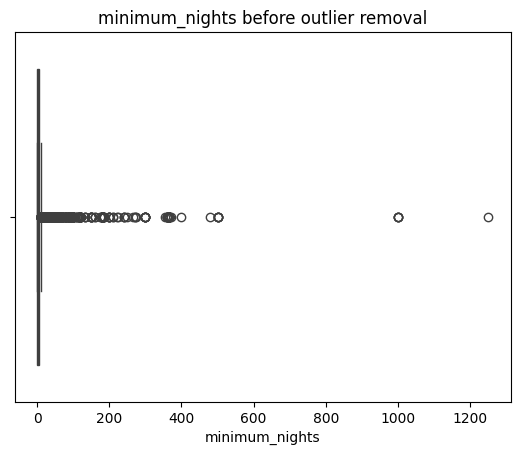

In [21]:
for col in ["price", "minimum_nights"]:
    sns.boxplot(x=data[col])
    plt.title(col + " before outlier removal")
    plt.show()

In [22]:
for col in ["price", "minimum_nights"]:
    limit = data[col].quantile(0.95)
    data = data[data[col] <= limit]

data = data[data["price"] > 0]

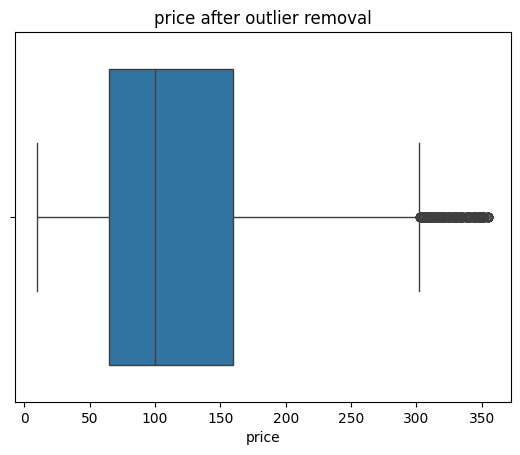

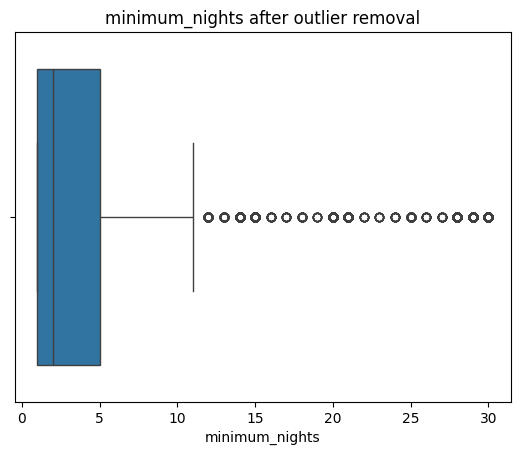

In [23]:
for col in ["price", "minimum_nights"]:
    sns.boxplot(x=data[col])
    plt.title(col + " after outlier removal")
    plt.show()

## Step 4: Feature selection and encoding

In [24]:
data = pd.get_dummies(
    data,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)


In [25]:
data = data.dropna()

print(data.head())

   latitude  longitude  price  minimum_nights  number_of_reviews  \
0  40.64749  -73.97237    149               1                  9   
1  40.75362  -73.98377    225               1                 45   
2  40.80902  -73.94190    150               3                  0   
3  40.68514  -73.95976     89               1                270   
4  40.79851  -73.94399     80              10                  9   

   reviews_per_month  calculated_host_listings_count  availability_365  \
0               0.21                               6               365   
1               0.38                               2               355   
2               0.00                               1               365   
3               4.64                               1               194   
4               0.10                               1                 0   

   neighbourhood_group_Brooklyn  neighbourhood_group_Manhattan  \
0                             1                              0   
1             

## Step 5: Split features and target

In [26]:
from sklearn.model_selection import train_test_split

X = data.drop("price", axis=1)
y = data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (36598, 13)
Testing data: (9150, 13)


## Step 6: Train and evaluate Linear Regression

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", round(r2, 3))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))


R2 Score: 0.487
MAE: 38.32
MSE: 2760.62
RMSE: 52.54


## Step 7: Residual analysis and conclusion

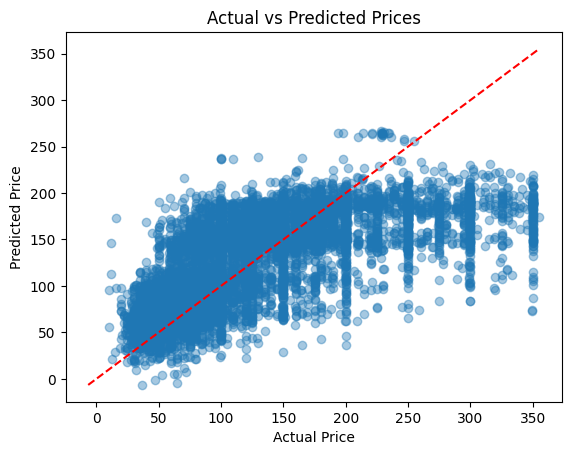

In [28]:
plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--")
plt.show()

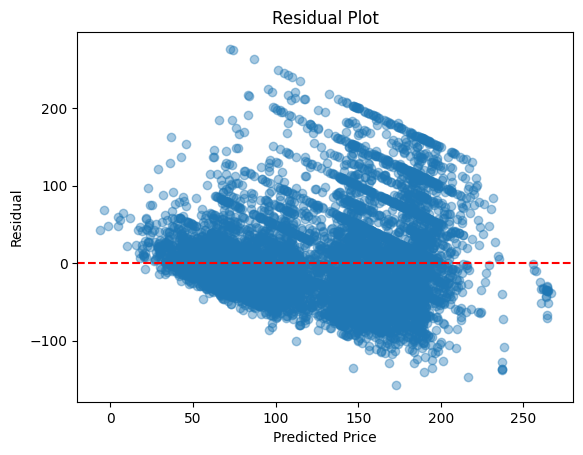

In [29]:
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()


In [30]:
result = pd.DataFrame({
    "Actual": y_test,
    "Error": abs(y_test - y_pred)
})
middle_price = result["Actual"].median()
result["Group"] = np.where(result["Actual"] <= middle_price,
                           "Cheaper", "Expensive")

print("Average error by price group:")
print(result.groupby("Group")["Error"].mean())

print("R2 Score:", round(r2, 3))
print("Average prediction error (MAE):", round(mae, 2))

Average error by price group:
Group
Cheaper      29.012085
Expensive    48.176113
Name: Error, dtype: float64
R2 Score: 0.487
Average prediction error (MAE): 38.32
